Lithium Carbonate Price Forecasting — Part 1: Data Import & Exploratory Analysis
Goal: understand and validate the consolidated monthly dataset before building forecasting models.

First we inspect the target price, coverage, missing data, and relationships among candidate predictors.

Important: the consolidated workbook contains a selected price series that changes source over time. The workbook's Selected target source column identifies the source used each month. Keep this source transition in mind when interpreting the long historical trend and when later evaluating models.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rdkit import Chem
from rdkit.Chem import AllChem, DataStructs

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics

df = pd.read_csv("lithium_data_consolidated.csv")

# Parse dates and sort chronologically
df["Month"] = pd.to_datetime(df["Month"], errors="coerce")
df = df.dropna(subset=["Month"]).sort_values("Month").reset_index(drop=True)

print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Date range:", df["Month"].min().date(), "to", df["Month"].max().date())

display(df.head())


Rows: 209
Columns: 36
Date range: 2009-06-01 to 2026-10-01


,Month,Selected lithium carbonate price (CNY/t),Selected target source,Lithium carbonate price (CNY/metric tonne),China spot lithium carbonate price (CNY/t) - CSV,Albemarle share price (USD/share),SQM share price (USD/ADR),Tesla share price (USD/share),LME nickel price (USD/metric tonne),LME copper price (USD/metric tonne),...,China spot price volume (CSV),China spot price change (%) - CSV,"Japan, Inventory - Lithium Batteries","China, Lithium Iron Phosphate Power Battery Sales","Japan, Shipments - Lithium Batteries","Japan, Production - Lithium Batteries","Japan, Import Prices, Yen Basis, Lithium Carbonates, Index, 2020 = 100","China, Pure Electric Vehicle Sales","China, Lithium Ion Battery Production",LME cobalt cash price (USD/metric tonne) - updated Datastream
0,2009-06-01,36000.0,China spot CSV,NaN,36000.0,NaN,NaN,NaN,NaN,NaN,...,NaN,-5.26,35840.0,NaN,37551.0,86577.0,NaN,NaN,1.611004e+08,NaN
1,2009-07-01,36000.0,China spot CSV,NaN,36000.0,NaN,NaN,NaN,NaN,NaN,...,NaN,0.00,30170.0,NaN,31598.0,89541.0,NaN,NaN,1.815160e+08,NaN
2,2009-08-01,36000.0,China spot CSV,NaN,36000.0,NaN,NaN,NaN,NaN,NaN,...,NaN,0.00,31600.0,NaN,28765.0,82362.0,NaN,NaN,1.708017e+08,NaN
3,2009-09-01,36000.0,China spot CSV,NaN,36000.0,NaN,NaN,NaN,NaN,NaN,...,NaN,0.00,31678.0,NaN,35090.0,88140.0,NaN,NaN,1.908061e+08,NaN
4,2009-10-01,36000.0,China spot CSV,NaN,36000.0,NaN,NaN,NaN,NaN,NaN,...,NaN,0.00,26179.0,NaN,35422.0,89872.0,NaN,NaN,1.837243e+08,NaN


In [2]:
df.info()

display(pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "non_missing": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(1)
}).sort_values("missing_percent"))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 209 entries, 0 to 208
Data columns (total 36 columns):
 #   Column                                                                  Non-Null Count  Dtype         
---  ------                                                                  --------------  -----         
 0   Month                                                                   209 non-null    datetime64[ns]
 1   Selected lithium carbonate price (CNY/t)                                209 non-null    float64       
 2   Selected target source                                                  209 non-null    object        
 3   Lithium carbonate price (CNY/metric tonne)                              90 non-null     float64       
 4   China spot lithium carbonate price (CNY/t) - CSV                        186 non-null    float64       
 5   Albemarle share price (USD/share)                                       90 non-null     float64       
 6   SQM share price (USD/ADR) 

,data_type,non_missing,missing,missing_percent
Month,datetime64[ns],209,0,0.0
Selected lithium carbonate price (CNY/t),float64,209,0,0.0
Selected target source,object,209,0,0.0
"Japan, Production - Lithium Batteries",float64,207,2,1.0
"Japan, Shipments - Lithium Batteries",float64,207,2,1.0
"Japan, Inventory - Lithium Batteries",float64,207,2,1.0
"Japan, Import Prices, Yen Basis, Lithium Carbonates, Index, 2020 = 100",float64,201,8,3.8
LME cobalt cash price (USD/metric tonne) - updated Datastream,float64,197,12,5.7
China spot lithium carbonate price (CNY/t) - CSV,float64,186,23,11.0
China spot price change (%) - CSV,float64,186,23,11.0


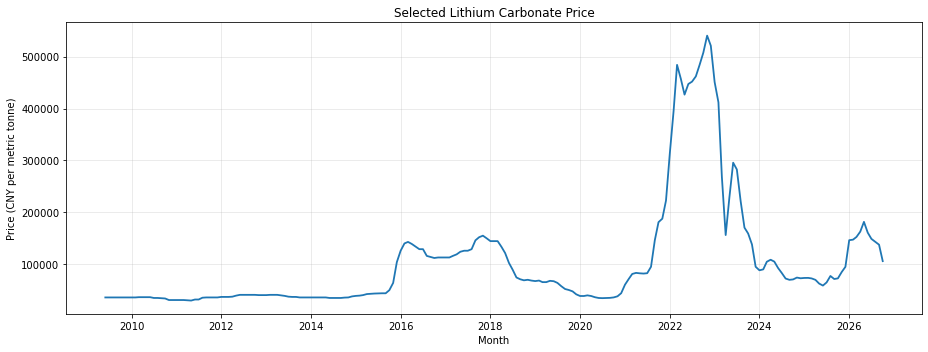

,observations,first_month,last_month,average_price
Selected target source,,,,
China spot CSV,119,2009-06-01,2019-04-01,63936.97
"Refinitiv weekly observations, monthly average",90,2019-05-01,2026-10-01,156035.12


In [3]:
TARGET = "Selected lithium carbonate price (CNY/t)"
SOURCE = "Selected target source"

if TARGET not in df.columns:
    raise KeyError(f"Target column not found: {TARGET}")

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(df["Month"], df[TARGET], linewidth=1.8)
ax.set_title("Selected Lithium Carbonate Price")
ax.set_xlabel("Month")
ax.set_ylabel("Price (CNY per metric tonne)")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

if SOURCE in df.columns:
    display(df.groupby(SOURCE, dropna=False).agg(
        observations=(TARGET, "count"),
        first_month=("Month", "min"),
        last_month=("Month", "max"),
        average_price=(TARGET, "mean")
    ).round(2))


In [4]:
duplicate_pairs = []
cols = list(df.columns)

for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        a, b = cols[i], cols[j]
        if df[a].equals(df[b]):
            duplicate_pairs.append((a, b))

print("Exact duplicate column pairs:")
for pair in duplicate_pairs:
    print(" -", pair)
if not duplicate_pairs:
    print("No exact duplicate columns detected.")


Exact duplicate column pairs:
No exact duplicate columns detected.


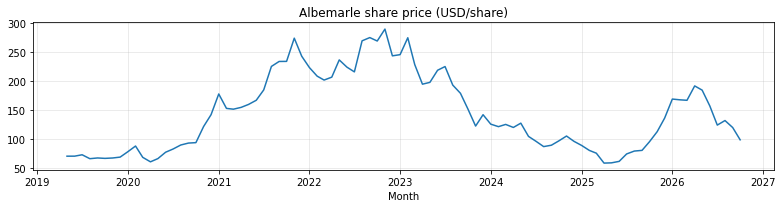

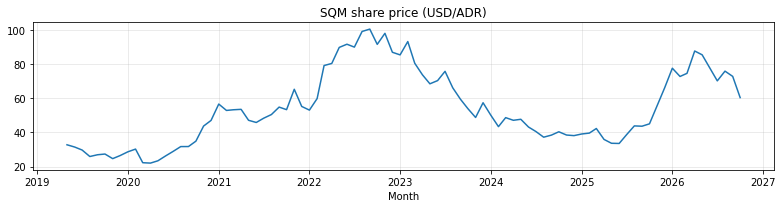

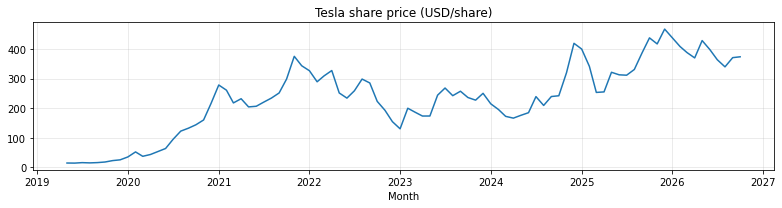

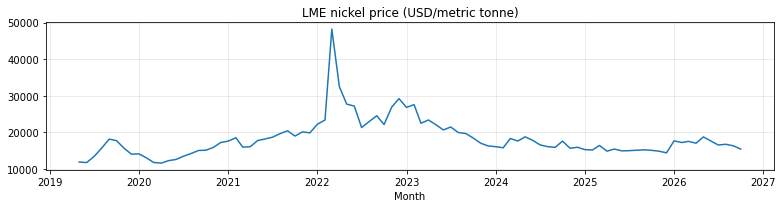

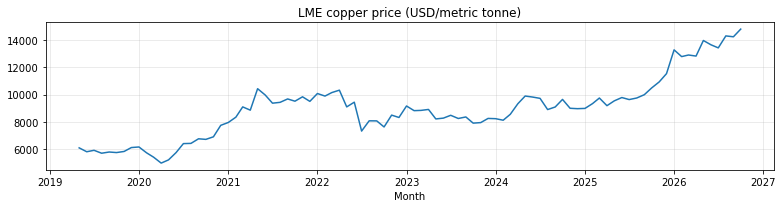

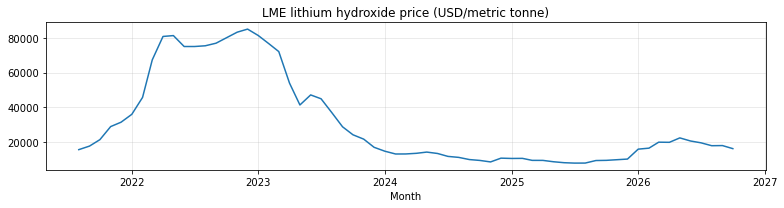

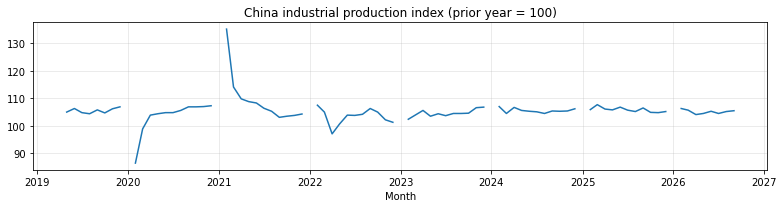

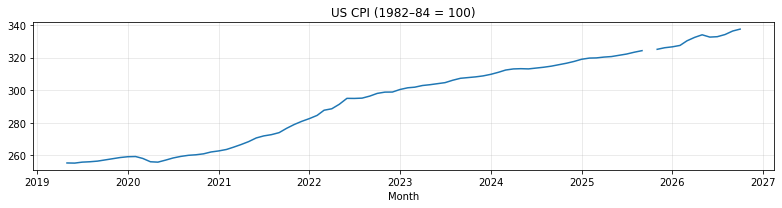

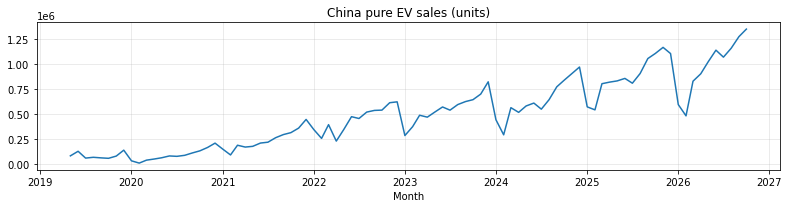

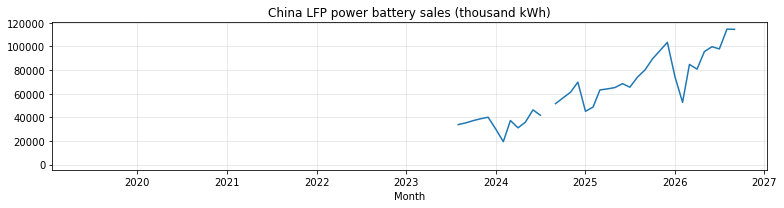

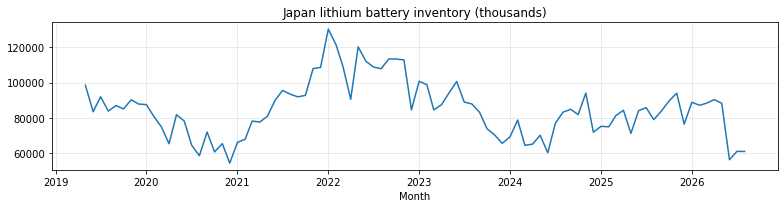

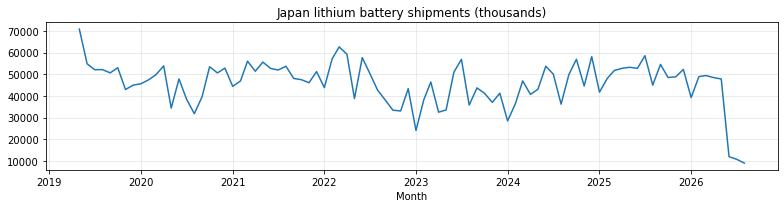

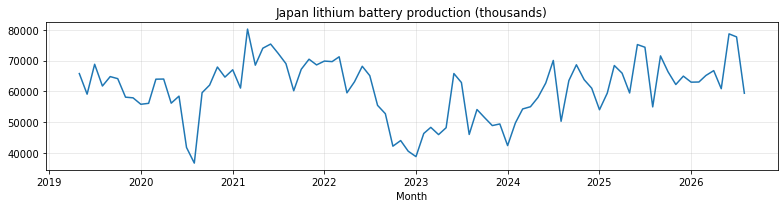

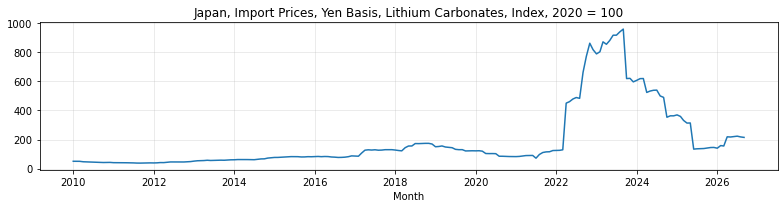

In [5]:
candidate_columns = [
    "Albemarle share price (USD/share)",
    "SQM share price (USD/ADR)",
    "Tesla share price (USD/share)",
    "LME nickel price (USD/metric tonne)",
    "LME copper price (USD/metric tonne)",
    "LME cobalt settlement price (USD/metric tonne)",
    "LME lithium hydroxide price (USD/metric tonne)",
    "China industrial production index (prior year = 100)",
    "US CPI (1982–84 = 100)",
    "China pure EV sales (units)",
    "China LFP power battery sales (thousand kWh)",
    "Japan lithium battery inventory (thousands)",
    "Japan lithium battery shipments (thousands)",
    "Japan lithium battery production (thousands)",
    "Japan, Import Prices, Yen Basis, Lithium Carbonates, Index, 2020 = 100"
]

candidate_columns = [c for c in candidate_columns if c in df.columns]

for col in candidate_columns:
    fig, ax = plt.subplots(figsize=(11, 3))
    ax.plot(df["Month"], df[col])
    ax.set_title(col)
    ax.set_xlabel("Month")
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


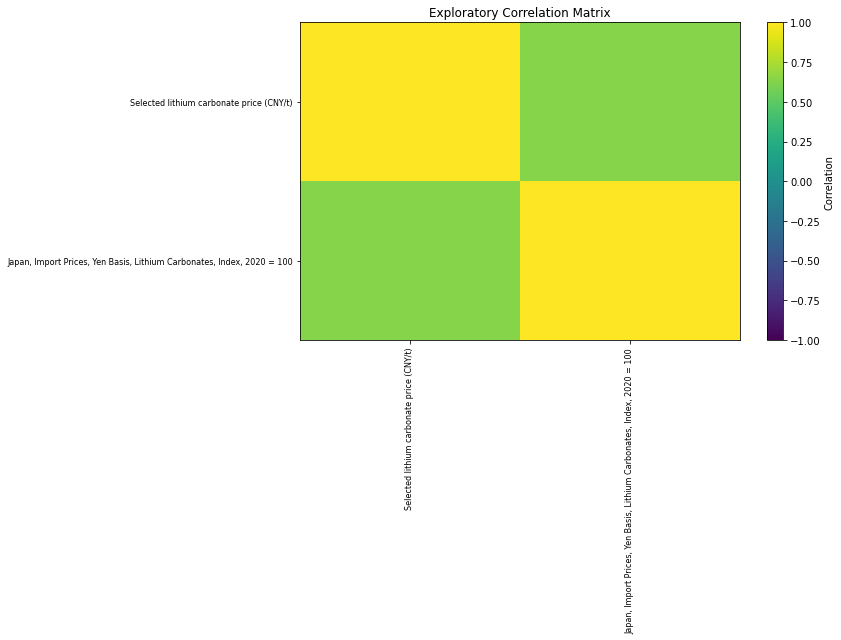

,correlation_with_target
Selected lithium carbonate price (CNY/t),1.000000
"Japan, Import Prices, Yen Basis, Lithium Carbonates, Index, 2020 = 100",0.634798


In [6]:
# Use the selected target and candidate variables only for this first correlation view.
corr_columns = [TARGET] + candidate_columns
corr_data = df[corr_columns].copy()

# Keep variables with at least 70% coverage in the full monthly panel.
coverage = corr_data.notna().mean()
corr_columns_kept = coverage[coverage >= 0.70].index.tolist()
corr_data = corr_data[corr_columns_kept]

corr = corr_data.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(12, 9))
im = ax.imshow(corr, vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.index)))
ax.set_xticklabels(corr.columns, rotation=90, fontsize=8)
ax.set_yticklabels(corr.index, fontsize=8)
ax.set_title("Exploratory Correlation Matrix")
fig.colorbar(im, ax=ax, label="Correlation")
plt.tight_layout()
plt.show()

display(corr[TARGET].sort_values(ascending=False).to_frame("correlation_with_target"))


In [7]:
coverage_table = pd.DataFrame({
    "first_available_month": df[candidate_columns].apply(lambda s: df.loc[s.first_valid_index(), "Month"] if s.first_valid_index() is not None else pd.NaT),
    "last_available_month": df[candidate_columns].apply(lambda s: df.loc[s.last_valid_index(), "Month"] if s.last_valid_index() is not None else pd.NaT),
    "observations": df[candidate_columns].notna().sum(),
    "coverage_percent": (df[candidate_columns].notna().mean() * 100).round(1)
}).sort_values("coverage_percent", ascending=False)

display(coverage_table)


,first_available_month,last_available_month,observations,coverage_percent
"Japan, Import Prices, Yen Basis, Lithium Carbonates, Index, 2020 = 100",2010-01-01,2026-09-01,201,96.2
Albemarle share price (USD/share),2019-05-01,2026-10-01,90,43.1
SQM share price (USD/ADR),2019-05-01,2026-10-01,90,43.1
Tesla share price (USD/share),2019-05-01,2026-10-01,90,43.1
LME nickel price (USD/metric tonne),2019-05-01,2026-10-01,90,43.1
LME copper price (USD/metric tonne),2019-05-01,2026-10-01,90,43.1
China pure EV sales (units),2019-05-01,2026-10-01,90,43.1
US CPI (1982–84 = 100),2019-05-01,2026-10-01,89,42.6
Japan lithium battery inventory (thousands),2019-05-01,2026-08-01,88,42.1
Japan lithium battery shipments (thousands),2019-05-01,2026-08-01,88,42.1


In [8]:
OUTPUT_FILE = Path("lithium_eda_working_data.csv")
df.to_csv(OUTPUT_FILE, index=False)
print(f"Saved: {OUTPUT_FILE.resolve()}")

NameError: name 'Path' is not defined